<a href="https://colab.research.google.com/github/Brown-Brayden/Midterm-Project-Econ_3916_Midterm.ipynb/blob/main/Econ_3916_Midterm_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 Midterm Project — Econometric Foundation

**ECON 3916 · Applied Data Analytics** · Topics 1-14 · 100 points · your role: Independent analyst

This is the **starter**: the structure of the project in rubric order. Fill the empty cells and keep every heading so the grader finds each section. The brief on Canvas has the full text of every section and the rubric. The grader reruns this notebook from the top, so every number, table and figure in your report must come from a cell here.

## Start here

Work top to bottom. What each part of this notebook is for:

1. **Data provenance**: where the file came from. It feeds Section 1 and your README.
2. **Section 1**: load the data into a DataFrame called `df`, then run the *Section 1 self-check* cell and answer the questions under it. Do this before the **Mon 2 Nov** checkpoint.
3. **Section 2**: figures, each with a caption that states a finding.
4. **Section 3**: the OLS model, with a draft committed by **Fri 6 Nov**.
5. **Section 4**: diagnostics, only after Topic 14.
6. **Section 5**: words only.
7. **Numbers my report quotes**: last. Every number in the report must be printed there.

The brief's *Six checks before you post* list the problems that came up most often in Checkpoint 1. Read them before you settle on your controls.

## Setup

Imports only. Add any others you need here, at the top.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Added for this project
import json
import time
from datetime import date
from pathlib import Path

import requests
from IPython.display import display
from matplotlib.ticker import FuncFormatter
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

## Data provenance

Fill these in when you download the data. They feed Section 1 and your README.

In [2]:
SOURCE_URL = "https://api.worldbank.org/v2/country/all/indicator/"   # World Bank WDI API; DataBank serves the same database (https://databank.worldbank.org/source/world-development-indicators)
DOWNLOAD_DATE = "2026-11-09"    # YYYY-MM-DD: the date of the API pull this notebook reports
FILE_NAME = "wdi_health_lifeexp_2000_2022.csv"   # optional: a DataBank CSV export saved in data/; if absent, the notebook pulls the API

# The four World Development Indicators series (all 217 economies, no aggregates, 2000-2022)
SERIES = {
    "SP.DYN.LE00.IN":    "life_exp",        # Life expectancy at birth, total (years)
    "SH.XPD.CHEX.PC.CD": "health_exp_pc",   # Current health expenditure per capita (current US$)
    "SP.URB.TOTL.IN.ZS": "urban_pct",       # Urban population (% of total population)
    "NY.GDP.PCAP.PP.KD": "gdp_pc_ppp",      # GDP per capita, PPP (constant international $)
}

**Who collected it, for what purpose, what is missing and why?**

- **Where I got it.** I pulled the four series through the World Bank's World Development Indicators (WDI) API on 2026-11-09. DataBank serves the same database.
- **Who.** The World Bank compiles WDI from other agencies. It doesn't measure any of these four series itself.
  - *Life expectancy* comes from the UN Population Division's *World Population Prospects*. It uses death registration where registration is complete, and censuses, surveys and demographic models where it is not.
  - *Health spending* comes from the WHO Global Health Expenditure Database, built from national health accounts under the System of Health Accounts 2011.
  - *Urban share* comes from the UN *World Urbanization Prospects*, using each country's own definition of "urban".
  - *GDP per capita at PPP* comes from national accounts, converted with price surveys from the International Comparison Program (ICP).
- **For what purpose.** WDI exists to compare development across countries and to track it over time, for example progress toward the Sustainable Development Goals. Nobody built it to estimate what health spending does. Each series is designed first of all to be comparable across countries, and that limits what it can tell us.
- **What is missing, and why.**
  - Health accounts are missing for small territories that aren't WHO members, and for a few closed or conflict-affected countries. WHO also publishes them with a lag, which is why the panel stops in 2022.
  - PPP GDP is missing where there is no ICP price survey: mostly the same small territories, plus closed or crisis economies.
  - Life expectancy and urbanization have no gaps, because the UN estimates them for every economy.

  Section 1 counts the gaps.

## Section 1: The Question and the Data (20 pts)

State the question in one sentence, and say why it matters and to whom. Describe the data as a product of measurement decisions, name the missingness mechanism (MCAR, MAR or MNAR) and defend the label. Build a summary-statistics table a reader can read without asking you a question.

In [3]:
# Section 1: load the data and reshape it into a panel where one row = one country in one year
YEARS = range(2000, 2023)
DATA_URL = ""   # optional: the raw GitHub link to a DataBank CSV export, instead of the API

# World Bank regional and income-group aggregates. The data should contain none; this drops any that slip in.
AGGREGATES = {"AFE", "AFW", "ARB", "CEB", "CSS", "EAP", "EAR", "EAS", "ECA", "ECS", "EMU", "EUU", "FCS",
              "HIC", "HPC", "IBD", "IBT", "IDA", "IDB", "IDX", "INX", "LAC", "LCN", "LDC", "LIC", "LMC",
              "LMY", "LTE", "MEA", "MIC", "MNA", "NAC", "OED", "OSS", "PRE", "PSS", "PST", "SAS", "SSA",
              "SSF", "SST", "TEA", "TEC", "TLA", "TMN", "TSA", "TSS", "UMC", "WLD"}


def read_databank_csv(where):
    """Read a DataBank CSV export (one row per country-series, one column per year) and return it in long form."""
    raw = pd.read_csv(where, na_values="..", encoding="utf-8-sig")
    raw = raw.dropna(subset=["Series Code"])            # drops the blank rows and source notes at the bottom
    raw = raw[raw["Series Code"].isin(SERIES)]
    print(f"Raw DataBank file: {raw.shape[0]:,} rows x {raw.shape[1]} columns (one row per country-series)")
    year_cols = [c for c in raw.columns if str(c)[:4].isdigit()]
    long = raw.melt(id_vars=["Country Name", "Country Code", "Series Code"], value_vars=year_cols,
                    var_name="year", value_name="value")
    long["year"] = long["year"].str[:4].astype(int)    # "2000 [YR2000]" -> 2000
    return long


def get_wb_json(url, params, tries=6):
    """One page from the World Bank API. It sometimes answers with a byte-order mark or an XML error page,
    so decode the raw bytes ourselves and retry before giving up."""
    problem = ""
    for attempt in range(1, tries + 1):
        try:
            resp = requests.get(url, params=params, timeout=120)
            text = resp.content.decode("utf-8-sig", errors="replace").strip()
            if resp.ok and text.startswith("["):
                data = json.loads(text)
                if isinstance(data, list) and len(data) == 2:
                    return data
            problem = f"HTTP {resp.status_code}: {text[:200]!r}"
        except (requests.RequestException, ValueError) as err:
            problem = repr(err)
        print(f"  API attempt {attempt}/{tries} did not return data ({problem}). Retrying...")
        time.sleep(4 * attempt)
    raise RuntimeError(f"The World Bank API did not return data for {url} {params}.\nLast response: {problem}")


def fetch_wdi_api():
    """The four series from the World Bank API, which serves the same WDI database as DataBank."""
    base = "https://api.worldbank.org/v2"
    meta = get_wb_json(f"{base}/country", {"format": "json", "per_page": 500})[1]
    names = {c["id"]: c["name"] for c in meta if c["region"]["value"].strip() != "Aggregates"}
    rows = []
    for code in SERIES:
        page, pages, before = 1, 1, len(rows)
        while page <= pages:
            info, records = get_wb_json(f"{base}/country/all/indicator/{code}",
                                        {"format": "json", "date": f"{min(YEARS)}:{max(YEARS)}",
                                         "per_page": 1000, "page": page})
            pages = int(info["pages"])
            rows += [{"Country Name": names[r["countryiso3code"]], "Country Code": r["countryiso3code"],
                      "Series Code": code, "year": int(r["date"]), "value": r["value"]}
                     for r in (records or []) if r["countryiso3code"] in names]
            page += 1
        print(f"  {code}: {len(rows) - before:,} country-year records")
    return pd.DataFrame(rows)


local_file = next((p for p in [Path("data") / FILE_NAME, Path(FILE_NAME)] if p.exists()), None)
if local_file is not None:
    long = read_databank_csv(local_file)
    DATA_ORIGIN = f"DataBank CSV ({local_file})"
elif DATA_URL:
    long = read_databank_csv(DATA_URL)
    DATA_ORIGIN = f"DataBank CSV ({DATA_URL})"
else:
    print("Downloading the four series from the World Bank API:")
    long = fetch_wdi_api()
    DATA_ORIGIN = f"World Bank API, fetched {date.today():%Y-%m-%d}"
print("Data used:", DATA_ORIGIN)

long["value"] = pd.to_numeric(long["value"], errors="coerce")
long = long[~long["Country Code"].isin(AGGREGATES) & long["year"].isin(YEARS)]

df = (long.pivot(index=["Country Name", "Country Code", "year"], columns="Series Code", values="value")
          .rename(columns=SERIES)
          .reset_index()
          .rename(columns={"Country Name": "country", "Country Code": "iso3"}))
df.columns.name = None
df = df[["country", "iso3", "year", *SERIES.values()]].sort_values(["country", "year"]).reset_index(drop=True)

# The two money variables enter the model in logs (Figure 1 shows why)
df["log_health_exp"] = np.log(df["health_exp_pc"])
df["log_gdp_pc"] = np.log(df["gdp_pc_ppp"])

print(f"Panel: {len(df):,} rows x {df.shape[1]} columns ({df['iso3'].nunique()} economies x "
      f"{df['year'].nunique()} years, {df['year'].min()}-{df['year'].max()})")
display(df.head())

  SP.DYN.LE00.IN: 4,991 country-year records
  SH.XPD.CHEX.PC.CD: 4,991 country-year records
  SP.URB.TOTL.IN.ZS: 4,991 country-year records
  NY.GDP.PCAP.PP.KD: 4,991 country-year records
Data used: World Bank API, fetched 2026-11-10
Panel: 4,991 rows x 9 columns (217 economies x 23 years, 2000-2022)


,country,iso3,year,life_exp,health_exp_pc,urban_pct,gdp_pc_ppp,log_health_exp,log_gdp_pc
0,Afghanistan,AFG,2000,55.005,NaN,18.558200,1617.826475,NaN,7.388839
1,Afghanistan,AFG,2001,55.511,NaN,18.741238,1454.110782,NaN,7.282150
2,Afghanistan,AFG,2002,56.225,16.706974,18.941248,1774.308743,2.815826,7.481166
3,Afghanistan,AFG,2003,57.171,17.746025,19.160035,1815.928200,2.876162,7.504352
4,Afghanistan,AFG,2004,57.810,21.423004,19.399359,1776.918207,3.064465,7.482636


In [4]:
# Section 1: what is missing, from whom, and what the complete-case sample leaves out
VARS = {"life_exp": "Life expectancy at birth (years)",
        "health_exp_pc": "Health spending per person (current US$)",
        "gdp_pc_ppp": "GDP per person, PPP (constant intl $)",
        "urban_pct": "Urban population (% of total)"}
MODEL_VARS = ["life_exp", "log_health_exp", "log_gdp_pc", "urban_pct"]

is_na = df[list(VARS)].isna()
missing = pd.DataFrame({
    "Missing country-years": is_na.sum(),
    "% of panel": (is_na.mean() * 100).round(1),
    "Economies with no data at all": is_na.groupby(df["iso3"]).all().sum(),
}).rename(index=VARS)
print("Table 1a. Missing values by variable")
display(missing)
print(f"Health spending is missing for {is_na.loc[df['year'] == min(YEARS), 'health_exp_pc'].sum()} economies "
      f"in {min(YEARS)} and {is_na.loc[df['year'] == max(YEARS), 'health_exp_pc'].sum()} in {max(YEARS)}.")

gaps = is_na.groupby(df["country"]).sum()
gaps["Total"] = gaps.sum(axis=1)
print(f"\nTable 1b. The 15 economies with the most missing country-years (out of {len(YEARS)} per variable)")
display(gaps.sort_values("Total", ascending=False).head(15).rename(columns=VARS))

# The analysis sample: country-years that have all four variables
sample = df.dropna(subset=MODEL_VARS).copy()
dropped = df.drop(sample.index)
print(f"\nComplete-case sample: {len(sample):,} country-years from {sample['iso3'].nunique()} countries; "
      f"{len(dropped):,} of {len(df):,} rows dropped ({len(dropped) / len(df):.1%}).")


# Is the selection ignorable? Life expectancy is almost always observed, so compare kept and dropped rows on it.
def le_profile(s):
    s = s.dropna()
    return pd.Series({"Country-years": len(s), "Mean": s.mean(), "10th pct": s.quantile(0.1),
                      "Median": s.median(), "90th pct": s.quantile(0.9)})


selection = pd.DataFrame({"Kept (complete cases)": le_profile(sample["life_exp"]),
                          "Dropped, life expectancy observed": le_profile(dropped["life_exp"])}).T.round(1)
print("\nTable 1c. Life expectancy (years) in kept vs. dropped country-years")
display(selection)

Table 1a. Missing values by variable


,Missing country-years,% of panel,Economies with no data at all
Life expectancy at birth (years),0,0.0,0
Health spending per person (current US$),645,12.9,24
"GDP per person, PPP (constant intl $)",467,9.4,18
Urban population (% of total),0,0.0,0


Health spending is missing for 33 economies in 2000 and 26 in 2022.

Table 1b. The 15 economies with the most missing country-years (out of 23 per variable)


,Life expectancy at birth (years),Health spending per person (current US$),"GDP per person, PPP (constant intl $)",Urban population (% of total),Total
country,,,,,
American Samoa,0,23,23,0,46
French Polynesia,0,23,23,0,46
Gibraltar,0,23,23,0,46
Channel Islands,0,23,23,0,46
Guam,0,23,23,0,46
British Virgin Islands,0,23,23,0,46
New Caledonia,0,23,23,0,46
"Korea, Dem. People's Rep.",0,23,23,0,46
Isle of Man,0,23,23,0,46



Complete-case sample: 4,222 country-years from 186 countries; 769 of 4,991 rows dropped (15.4%).

Table 1c. Life expectancy (years) in kept vs. dropped country-years


,Country-years,Mean,10th pct,Median,90th pct
Kept (complete cases),4222.0,70.1,57.8,71.5,80.9
"Dropped, life expectancy observed",769.0,74.6,63.1,76.5,82.4


In [5]:
# Section 1: summary statistics for the analysis sample (Table 2)
def summary_table(data):
    stats = {}
    for col, label in VARS.items():
        s = data[col].dropna()
        stats[label] = {"N": len(s), "Mean": s.mean(), "Std. dev.": s.std(), "Min": s.min(),
                        "Median": s.median(), "Max": s.max(), "Skew": s.skew()}
    return pd.DataFrame(stats).T


summary = summary_table(sample)
print(f"Table 2. Summary statistics: complete-case sample, {len(sample):,} country-years, "
      f"{sample['iso3'].nunique()} countries, {sample['year'].min()}-{sample['year'].max()}")
display(summary.style.format({"N": "{:,.0f}", "Mean": "{:,.1f}", "Std. dev.": "{:,.1f}", "Min": "{:,.1f}",
                              "Median": "{:,.1f}", "Max": "{:,.1f}", "Skew": "{:.2f}"}))
print("Health spending is in current US dollars at market exchange rates. GDP per person is in constant international\n"
      "dollars at purchasing-power parity. A skew above about 1 means a long right tail.")

# The extremes behind Table 2's minimum and maximum life expectancy
print("\nThe five lowest and three highest life expectancies in the sample:")
extremes = pd.concat([sample.nsmallest(5, "life_exp"), sample.nlargest(3, "life_exp")])
display(extremes[["country", "year", "life_exp", "health_exp_pc", "gdp_pc_ppp", "urban_pct"]].round(1))

Table 2. Summary statistics: complete-case sample, 4,222 country-years, 186 countries, 2000-2022


,N,Mean,Std. dev.,Min,Median,Max,Skew
Life expectancy at birth (years),"4,222",70.1,8.7,14.7,71.5,85.7,-0.72
Health spending per person (current US$),"4,222",931.4,"1,631.4",4.2,264.1,"12,586.2",2.79
"GDP per person, PPP (constant intl $)","4,222","21,754.2","23,593.8",712.0,"13,136.0","149,025.1",1.88
Urban population (% of total),"4,222",57.0,22.7,8.0,58.2,100.0,-0.08


Health spending is in current US dollars at market exchange rates. GDP per person is in constant international
dollars at purchasing-power parity. A skew above about 1 means a long right tail.

The five lowest and three highest life expectancies in the sample:


,country,year,life_exp,health_exp_pc,gdp_pc_ppp,urban_pct
860,Central African Republic,2009,14.7,21.4,1402.7,38.5
873,Central African Republic,2022,18.8,47.9,1136.8,43.3
870,Central African Republic,2019,31.5,35.8,1145.1,41.8
865,Central African Republic,2014,40.3,18.7,1001.9,39.6
872,Central African Republic,2021,40.3,46.3,1128.6,42.9
3794,San Marino,2022,85.7,3875.0,70887.6,97.1
3791,San Marino,2019,85.3,3801.2,60171.1,97.1
3790,San Marino,2018,85.1,3969.4,59194.0,97.1


In [6]:
# Section 1 self-check: run once your data is loaded into a DataFrame called df.
# It prints what Section 1 has to report. It doesn't judge your choices: answer the questions below.
UNIT = "country-year"                               # one row is one what? e.g. "county" or "country-year"
OUTCOME = "life_exp"                                # your dependent variable's column name
MAIN_X = "log_health_exp"                           # your main explanatory variable's column name
CONTROLS = ["log_gdp_pc", "urban_pct", "year"]      # every other column in your model

if "df" in globals():
    print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   One row is: {UNIT or '(fill in UNIT)'}")
    cols = [c for c in [OUTCOME, MAIN_X, *CONTROLS] if c]
    absent = [c for c in cols if c not in df.columns]
    if absent:
        print("Not in df:", absent)
    present = [c for c in cols if c in df.columns]
    if present:
        print("\nMissing values per column:")
        print(df[present].isna().sum().to_string())
    if OUTCOME in df.columns and pd.api.types.is_numeric_dtype(df[OUTCOME]):
        print(f"\nSkew of {OUTCOME}: {df[OUTCOME].skew():.2f} (above about 1, consider a log)")
else:
    print("Load your data into a DataFrame called df first, then run this cell.")

Rows: 4,991   Columns: 9   One row is: country-year

Missing values per column:
life_exp            0
log_health_exp    645
log_gdp_pc        467
urban_pct           0
year                0

Skew of life_exp: -0.83 (above about 1, consider a log)


**Answer before you go on.**

1. For each control: does your main explanatory variable change it? If yes, it is on the path from X to Y. Drop it, or run with and without and say what each version measures.
2. Are all your variables in the same units and for the same years?
3. If your question is about a policy, where is the period before it?

**My answers.**

1. **Controls.**
   - *Log GDP per person.* Mostly no, but not entirely. Income drives health spending far more than spending drives income, so GDP is mainly a confounder. Two small paths run the other way, though. Health spending is final consumption, so it is counted inside GDP. And a healthier population works more and earns more, so part of GDP may sit on the path from spending to life expectancy. So I run the model both without income (model 2 in Section 3) and with it (model 3):
     - *Without income*, the spending coefficient measures how life expectancy differs with spending, including everything that comes with being richer.
     - *With income*, it measures the difference between countries at the same income. It may understate any part of spending's effect that works through income.
   - *Urban population share.* No. Health spending doesn't move people into cities on any scale that matters; urbanization follows industrialization and the shift out of farming. Urbanization does affect both sides, though. Urban populations are easier and costlier to serve, so they raise spending. Urban living also changes mortality directly, through sanitation, distance to clinics and pollution. That makes urbanization a confounder, not a mediator.
   - *Year.* Health spending can't change the calendar. Year dummies absorb shocks common to every country (COVID-19 in 2020–21, worldwide medical progress). They also absorb US-dollar inflation (see 2).
2. **Units and years.**
   - All four series are annual and cover the same years, 2000–2022.
   - The money units don't match. Health spending is in *current* US dollars at *market exchange rates*. GDP per person is in *constant* international dollars at *purchasing-power parity*.
     - In logs, US inflation adds the same amount to every country's log spending in a given year, so the year dummies remove it exactly.
     - What they can't remove is the gap between exchange rates and PPP: a dollar of health spending buys more care in a low-income country than the exchange rate implies. Section 5 treats this as a measurement threat.
   - Urbanization is a percentage and life expectancy is in years.
3. **Policy and pre-period.** The question isn't about a policy with a start date. It compares countries and years with different levels of spending, so there is no pre-period to find. That is also why the result is an association, not the effect of a policy (Section 5).

**The question.** Across countries from 2000 to 2022, is higher health spending per person associated with longer life expectancy once income and urbanization are held constant? The answer matters to finance ministries and donors deciding how much to put into health, and to the WHO and the World Bank, which encourage countries to spend more. If extra spending buys little life expectancy among countries at the same income, the case for bigger health budgets has to rest on how the money is spent, not on how much.

**The data as a product of measurement.** The data are a country-year panel from the World Bank's World Development Indicators: 217 economies × 23 years = 4,991 rows. I pulled the four series from the WDI API on 2026-11-09 (DataBank serves the same database) and reshaped them so that one row is one country in one year. Each variable is the result of choices someone else made:

- *Life expectancy at birth* is a period measure: the years a newborn would live if this year's death rates at each age held for life. It doesn't follow any real cohort. Where death registration is incomplete, it is a UN estimate built from censuses, surveys and models. In poor countries it is therefore partly modelled, not counted.
- *Current health expenditure per person* follows the System of Health Accounts. It counts government, insurance, out-of-pocket and donor spending on health goods and services, but not capital investment such as new hospitals. It is converted to US dollars at market exchange rates, which understates how much care a dollar buys where prices are low.
- *GDP per person at PPP* rests on International Comparison Program price surveys. Between survey years, and for countries outside the surveys, price levels are extrapolated.
- *Urban share* uses each country's own definition of "urban": a population threshold in some countries, administrative status in others. The same share means somewhat different things in different places.

**Missingness.** Table 1a counts the gaps. Life expectancy and urbanization have none. Health spending is missing for 12.9% of country-years and PPP GDP for 9.4%. 24 economies have no health-spending data at all, and 18 have no PPP GDP. Table 1b shows who is missing:

- *Mostly small territories that aren't WHO members.* They file no health accounts and sit outside the ICP price surveys: American Samoa, Guam, Gibraltar, the Channel Islands, the Isle of Man and New Caledonia, among others.
- *A few closed or conflict-affected economies:* North Korea, Venezuela and South Sudan.

Dropping incomplete rows leaves a complete-case sample of 4,222 country-years from 186 countries. 769 rows (15.4% of the panel) are dropped.

I label the mechanism **MAR (missing at random)**:

- *It isn't MCAR.* Table 1c shows the dropped rows are not a random draw. Their life expectancy averages 74.6 years, against 70.1 in the sample, and is higher at both the 10th percentile (63.1 vs. 57.8) and the 90th (82.4 vs. 80.9). That is because most dropped rows are rich small territories.
- *It is MAR.* Whether a row is missing follows from known facts about the economy, such as whether it is a WHO member and whether it takes part in ICP price surveys. It doesn't follow from how much that economy actually spends or earns.
- *MNAR can't be ruled out for a few cases.* In the closed or crisis economies, the missing values are probably extreme (very low income or spending), so their gaps may depend on the values themselves. They account for a minority of the dropped rows.

In my checkpoint 1 post I expected the gaps to fall mostly on poor, unstable countries. The counts show they fall mostly on small, rich territories. The sample therefore consists mostly of sovereign countries that report health accounts. It leaves out long-lived small territories at the top of the distribution and a few crisis states at the bottom, and the estimates describe the 186 countries in it.

**Summary statistics.** Table 2 describes the analysis sample:

- *Life expectancy* averages 70.1 years (SD 8.7, median 71.5) and runs from 14.7 to 85.7 (San Marino, 2022). The bottom of that range is suspect. The five lowest values all belong to the Central African Republic: 14.7 years in 2009, 18.8 in 2022, 31.5 in 2019, and 40.3 in both 2014 and 2021 (the table under Table 2).
  - The two lowest would mean a mortality catastrophe far worse than anything else in the panel.
  - The series also jumps around from year to year.
  - I therefore treat those values as probable estimation errors in the UN series. I keep them in the sample rather than edit the data, and Section 4 checks how much the Central African Republic moves the results.
- *Health spending* has a median of \$264 per person but a mean of \$931, and runs from \$4.20 to \$12,586. It is strongly right-skewed (skew 2.79).
- *GDP per person* is right-skewed too (skew 1.88), with a median of \$13,136 and a mean of \$21,754. That is why both money variables enter the model in logs.
- *Urbanization* averages 57% (SD 22.7) and spans almost the whole possible range, from 8% to 100%.

## Section 2: Descriptive Evidence (20 pts)

Show the reader the data before any model. At least two figures, each with a caption that states its finding, not its variables. Chapter 3's standards for axes. If the outcome is skewed, show it and say what you will do about it.

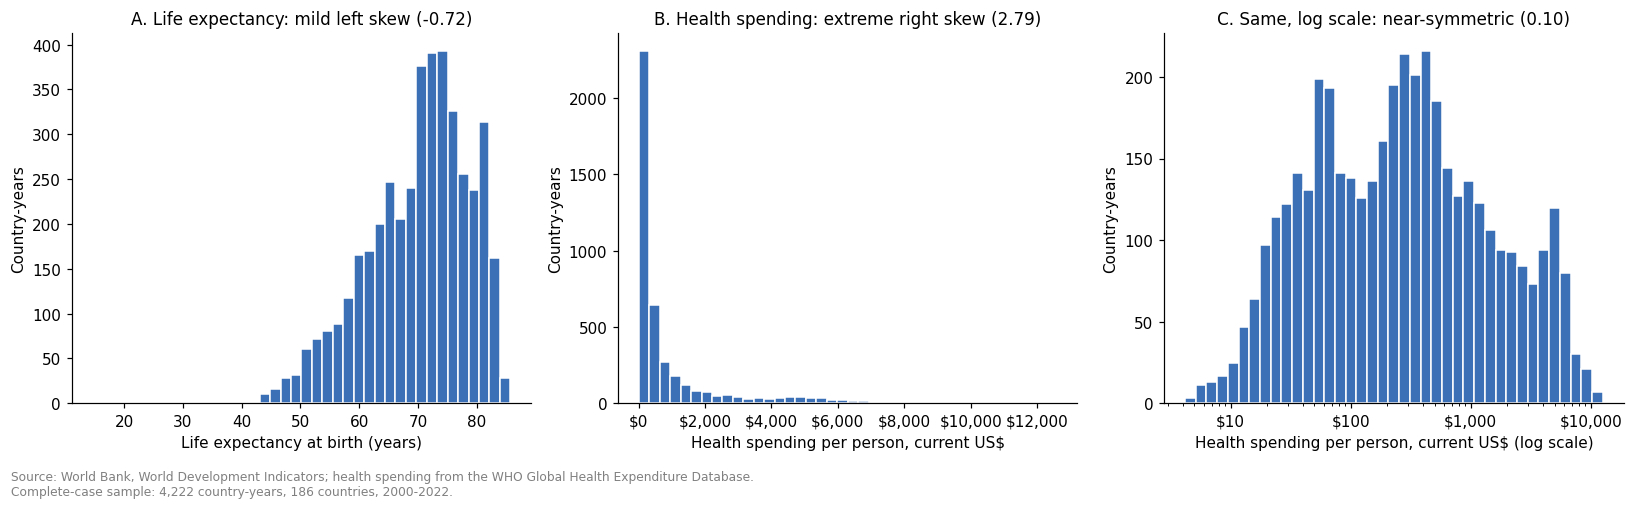

Skew of GDP per person: 1.88 raw, -0.14 in logs


In [7]:
# Section 2, Figure 1: the distributions, and why health spending enters the model in logs
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.labelsize": 10})
DOLLARS = FuncFormatter(lambda x, _: f"${x:,.0f}")     # tick labels for dollar axes
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)                            # a PNG copy of every figure, for the report
BLUE = "#3B6FB6"
SOURCE_NOTE = ("Source: World Bank, World Development Indicators; health spending from the WHO Global Health "
               "Expenditure Database.\n"
               f"Complete-case sample: {len(sample):,} country-years, {sample['iso3'].nunique()} countries, "
               f"{sample['year'].min()}-{sample['year'].max()}.")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
axes[0].hist(sample["life_exp"], bins=40, color=BLUE, edgecolor="white")
axes[0].set(title=f"A. Life expectancy: mild left skew ({sample['life_exp'].skew():.2f})",
            xlabel="Life expectancy at birth (years)", ylabel="Country-years")
axes[1].hist(sample["health_exp_pc"], bins=40, color=BLUE, edgecolor="white")
axes[1].xaxis.set_major_formatter(DOLLARS)
axes[1].set(title=f"B. Health spending: extreme right skew ({sample['health_exp_pc'].skew():.2f})",
            xlabel="Health spending per person, current US$", ylabel="Country-years")
log_bins = np.logspace(np.log10(sample["health_exp_pc"].min()), np.log10(sample["health_exp_pc"].max()), 40)
axes[2].hist(sample["health_exp_pc"], bins=log_bins, color=BLUE, edgecolor="white")
axes[2].set_xscale("log")
axes[2].xaxis.set_major_formatter(DOLLARS)
axes[2].set(title=f"C. Same, log scale: near-symmetric ({sample['log_health_exp'].skew():.2f})",
            xlabel="Health spending per person, current US$ (log scale)", ylabel="Country-years")
fig.tight_layout()
fig.text(0.01, -0.06, SOURCE_NOTE, fontsize=8, color="gray")
fig.savefig(FIG_DIR / "fig1_distributions.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Skew of GDP per person: {sample['gdp_pc_ppp'].skew():.2f} raw, {sample['log_gdp_pc'].skew():.2f} in logs")

**Figure 1. Health spending is extremely right-skewed in dollars and close to symmetric in logs, so it enters the model in logs.**

- **Panel B:** the median country-year spends \$264 per person, but a long tail of rich countries pulls the mean up to \$931. The raw skew is 2.79.
- **Panel C:** on a log scale the skew falls to 0.10. GDP per person behaves the same way (skew 1.88 raw, −0.14 in logs), so it is logged too.
- **Panel A:** life expectancy is only mildly left-skewed (skew −0.72), so it stays in years, which are easier to interpret. The empty stretch on the left reaches down to the Central African Republic's implausible values (Section 1).

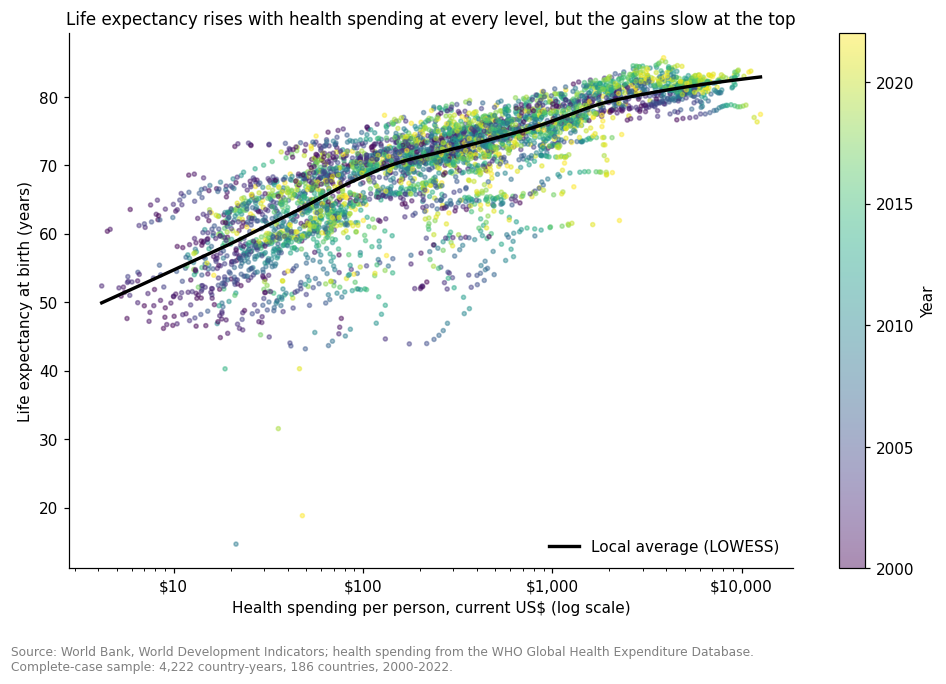

Correlation of life expectancy with log health spending: 0.81
Local-average life expectancy at selected spending levels (years):
$30        61.0
$100       68.3
$300       72.4
$1,000     76.5
$3,000     80.4
$10,000    82.6


In [8]:
# Section 2, Figure 2: life expectancy against health spending, every country-year in the sample
fig, ax = plt.subplots(figsize=(9, 5.8))
points = ax.scatter(sample["health_exp_pc"], sample["life_exp"], c=sample["year"], cmap="viridis", s=7, alpha=0.45)
curve = lowess(sample["life_exp"], sample["log_health_exp"], frac=0.3)
ax.plot(np.exp(curve[:, 0]), curve[:, 1], color="black", lw=2.2, label="Local average (LOWESS)")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(DOLLARS)
ax.set(xlabel="Health spending per person, current US$ (log scale)", ylabel="Life expectancy at birth (years)",
       title="Life expectancy rises with health spending at every level, but the gains slow at the top")
fig.colorbar(points, ax=ax, label="Year", ticks=range(2000, 2023, 5), format="%d")
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
fig.text(0.01, -0.06, SOURCE_NOTE, fontsize=8, color="gray")
fig.savefig(FIG_DIR / "fig2_life_exp_vs_spending.png", dpi=200, bbox_inches="tight")
plt.show()

corr_le_loghealth = sample[["life_exp", "log_health_exp"]].corr().iloc[0, 1]
LOWESS_AT = [30, 100, 300, 1000, 3000, 10000]
lowess_at = pd.Series(np.interp(np.log(LOWESS_AT), curve[:, 0], curve[:, 1]), index=LOWESS_AT)
print(f"Correlation of life expectancy with log health spending: {corr_le_loghealth:.2f}")
print("Local-average life expectancy at selected spending levels (years):")
print(lowess_at.rename(lambda a: f"${a:,}").round(1).to_string())

**Figure 2. Life expectancy rises with health spending at every level, fastest among the lowest spenders and slowest among the highest.**

- On the local-average curve, going from \$30 to \$100 per person goes with 7.3 more years, and from \$100 to \$1,000 with 8.1 more. From \$1,000 to \$10,000 the gain is 6.1 years, and only 2.2 of those come above \$3,000.
- The correlation between life expectancy and log spending is 0.81.
- The colours show the whole cloud drifting right over time. That is partly real growth and partly US inflation, since spending is in current dollars. It is one reason the model includes year effects.
- The isolated points near the bottom are the Central African Republic's implausible values (Section 1).

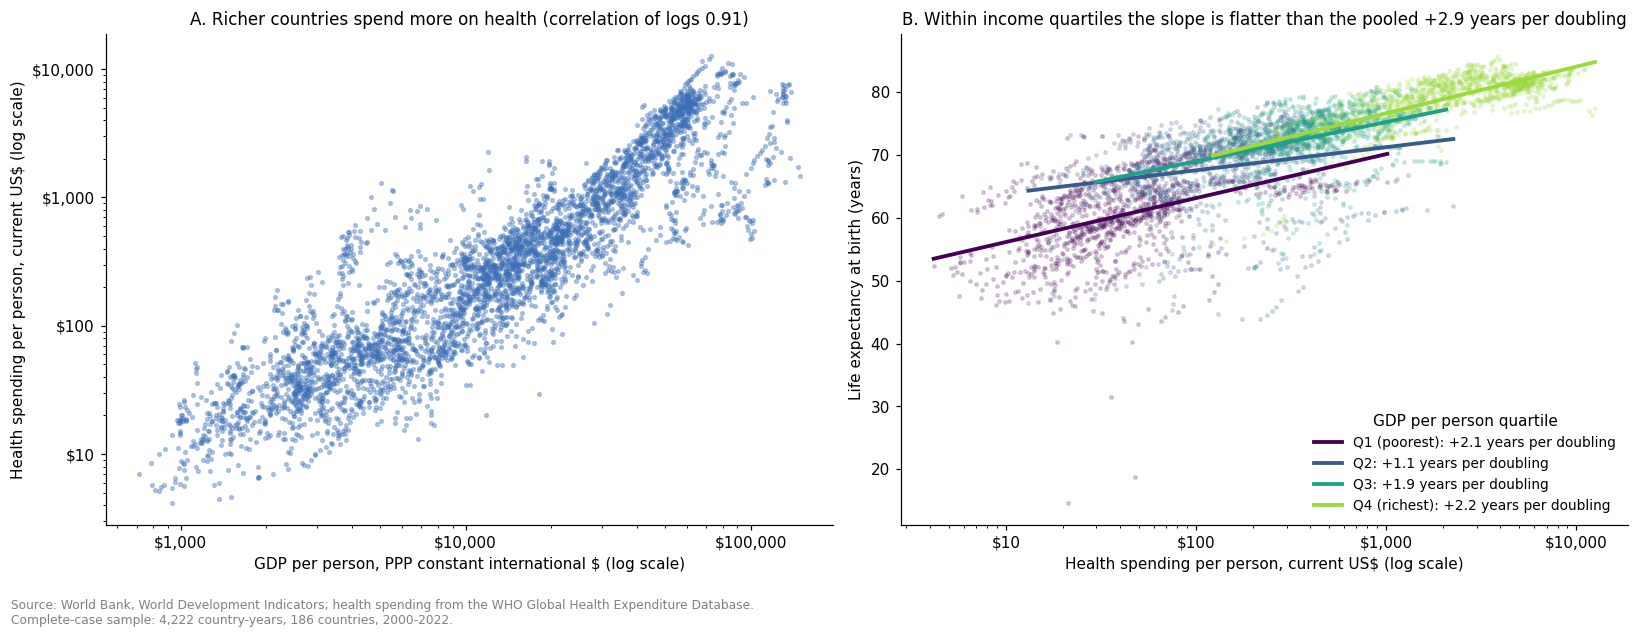

Q1 (poorest)    2.11
Q2              1.11
Q3              1.88
Q4 (richest)    2.23


In [9]:
# Section 2, Figure 3: spending tracks income; within an income band the spending gradient is flatter
QUARTILE_LABELS = ["Q1 (poorest)", "Q2", "Q3", "Q4 (richest)"]
sample["gdp_quartile"] = pd.qcut(sample["gdp_pc_ppp"], 4, labels=QUARTILE_LABELS)
corr_health_gdp = sample[["log_health_exp", "log_gdp_pc"]].corr().iloc[0, 1]
pooled_slope = np.polyfit(sample["log_health_exp"], sample["life_exp"], 1)[0]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
ax = axes[0]
ax.scatter(sample["gdp_pc_ppp"], sample["health_exp_pc"], s=6, alpha=0.35, color=BLUE)
ax.set_xscale("log")
ax.set_yscale("log")
ax.xaxis.set_major_formatter(DOLLARS)
ax.yaxis.set_major_formatter(DOLLARS)
ax.set(xlabel="GDP per person, PPP constant international $ (log scale)",
       ylabel="Health spending per person, current US$ (log scale)",
       title=f"A. Richer countries spend more on health (correlation of logs {corr_health_gdp:.2f})")

ax = axes[1]
quartile_slopes = {}
for label, color in zip(QUARTILE_LABELS, plt.cm.viridis(np.linspace(0, 0.85, 4))):
    g = sample[sample["gdp_quartile"] == label]
    slope, intercept = np.polyfit(g["log_health_exp"], g["life_exp"], 1)
    quartile_slopes[label] = slope * np.log(2)          # years of life expectancy per doubling of spending
    xs = np.linspace(g["log_health_exp"].min(), g["log_health_exp"].max(), 50)
    ax.scatter(g["health_exp_pc"], g["life_exp"], s=5, alpha=0.18, color=color)
    ax.plot(np.exp(xs), intercept + slope * xs, color=color, lw=2.5,
            label=f"{label}: {quartile_slopes[label]:+.1f} years per doubling")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(DOLLARS)
ax.set(xlabel="Health spending per person, current US$ (log scale)", ylabel="Life expectancy at birth (years)",
       title=f"B. Within income quartiles the slope is flatter than the pooled {pooled_slope * np.log(2):+.1f} years per doubling")
ax.legend(title="GDP per person quartile", loc="lower right", frameon=False, fontsize=9)
fig.tight_layout()
fig.text(0.01, -0.06, SOURCE_NOTE, fontsize=8, color="gray")
fig.savefig(FIG_DIR / "fig3_income.png", dpi=200, bbox_inches="tight")
plt.show()

print(pd.Series(quartile_slopes, name="Years of life expectancy per doubling of health spending").round(2).to_string())

**Figure 3. Health spending moves almost in lockstep with income, and at a given income the spending gradient is flatter.**

- **Panel A:** the correlation between log spending and log GDP per person is 0.91, so much of the pooled association in Figure 2 is the association with being richer.
- **Panel B:** within an income quartile, a doubling of spending goes with 1.11 to 2.23 more years of life expectancy. Pooled across all countries, it goes with 2.89 more years.

Spending still matters at a given income, but less than the raw picture suggests. That is why the model has to hold income constant.

**What the data show before any model.**

- **Figure 1:** health spending and GDP per person are so right-skewed that a model in dollars would be driven by a few rich countries. Logs make both close to symmetric. They also turn coefficients into "per percent" effects, which is the natural way to compare a country spending \$50 per person with one spending \$5,000. Life expectancy needs no transformation.
- **Figure 2:** the raw association is strong (correlation 0.81) and positive. It is steepest among the lowest spenders, steady from about \$100 to \$3,000 per person, and flatter above that. A model that is linear in log spending captures the average gradient. Section 4 checks the residuals for the bend at the top.
- **Figure 3:** this figure is the reason for the model. Spending and income are close to collinear (correlation of logs 0.91). Within an income band the spending gradient is flatter: 1.11 to 2.23 years per doubling, against 2.89 pooled. Holding income constant should therefore shrink the spending coefficient.

How much it shrinks, and whether anything is left, is the job of Section 3. The near-collinearity is also a warning: the spending and income coefficients will be less precise than the sample size suggests (Section 4, VIF).

## Section 3: The Model (25 pts)

Fit a multivariate OLS model and report it in a formatted regression table (coefficients, standard errors, N, R-squared), not a `summary()` dump. Interpret at least two coefficients in full: magnitude, units, direction, precision. For every control, say whether it blocks a confounding path or adds precision, and what would make it a bad control (Chapter 10). OLS only: no difference-in-differences estimate.

In [10]:
# Section 3: four OLS models, building up to the main specification (4)
FORMULAS = {
    "(1)": "life_exp ~ log_health_exp",
    "(2)": "life_exp ~ log_health_exp + urban_pct",
    "(3)": "life_exp ~ log_health_exp + log_gdp_pc + urban_pct",
    "(4)": "life_exp ~ log_health_exp + log_gdp_pc + urban_pct + C(year)",
}
MAIN = "(4)"
country_groups = pd.factorize(sample["iso3"])[0]     # one cluster per country: its years are not independent draws
models = {name: smf.ols(f, data=sample).fit(cov_type="cluster", cov_kwds={"groups": country_groups})
          for name, f in FORMULAS.items()}
main = models[MAIN]
main_ols = smf.ols(FORMULAS[MAIN], data=sample).fit()   # same coefficients, classical SEs: for the Section 4 diagnostics

LABELS = {"log_health_exp": "Log health spending per person",
          "log_gdp_pc": "Log GDP per person (PPP)",
          "urban_pct": "Urban population (%)",
          "Intercept": "Constant"}


def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""


def regression_table(models, labels):
    """Coefficients with clustered standard errors underneath, then the fit statistics."""
    rows, index = [], []
    for var, label in labels.items():
        rows.append([f"{m.params[var]:.3f}{stars(m.pvalues[var])}" if var in m.params else "" for m in models.values()])
        rows.append([f"({m.bse[var]:.3f})" if var in m.params else "" for m in models.values()])
        index += [label, ""]
    footer = {
        "Year fixed effects": ["Yes" if "C(year)" in FORMULAS[name] else "No" for name in models],
        "Countries": [f"{sample['iso3'].nunique()}" for _ in models],
        "Observations (country-years)": [f"{int(m.nobs):,}" for m in models.values()],
        "R-squared": [f"{m.rsquared:.3f}" for m in models.values()],
        "Adjusted R-squared": [f"{m.rsquared_adj:.3f}" for m in models.values()],
    }
    for label, values in footer.items():
        rows.append(values)
        index.append(label)
    return pd.DataFrame(rows, index=index, columns=list(models))


reg_table = regression_table(models, LABELS)
print("Table 3. OLS estimates. Dependent variable: life expectancy at birth (years)")
display(reg_table)
print("Standard errors clustered by country in parentheses. * p<0.10, ** p<0.05, *** p<0.01.\n"
      "Health spending is in current US$ and GDP per person in constant PPP international $, both in natural logs.\n"
      "Model (4) adds a dummy for each year (2000 is the base year).")

Table 3. OLS estimates. Dependent variable: life expectancy at birth (years)


,(1),(2),(3),(4)
Log health spending per person,4.163***,3.745***,1.782***,1.570***
,(0.174),(0.270),(0.468),(0.525)
Log GDP per person (PPP),,,3.738***,3.963***
,,,(0.788),(0.835)
Urban population (%),,0.043*,0.006,0.007
,,(0.024),(0.024),(0.024)
Constant,46.930***,46.784***,24.674***,22.865***
,(1.153),(1.166),(4.787),(5.166)
Year fixed effects,No,No,No,Yes
Countries,186,186,186,186


Standard errors clustered by country in parentheses. * p<0.10, ** p<0.05, *** p<0.01.
Health spending is in current US$ and GDP per person in constant PPP international $, both in natural logs.
Model (4) adds a dummy for each year (2000 is the base year).


In [11]:
# Section 3: the main model's coefficients in units a reader can use (clustered 95% confidence intervals)
LN2, LN11 = np.log(2), np.log(1.1)
ci = main.conf_int()
scale = {"Health spending per person +10%": ("log_health_exp", LN11),
         "Health spending per person doubles": ("log_health_exp", LN2),
         "GDP per person doubles": ("log_gdp_pc", LN2),
         "Urban share +10 percentage points": ("urban_pct", 10)}
interp = pd.DataFrame({change: {"Years of life expectancy": main.params[v] * k,
                                "95% CI low": ci.loc[v, 0] * k,
                                "95% CI high": ci.loc[v, 1] * k}
                       for change, (v, k) in scale.items()}).T.round(2)
print("Table 4. What the main model's coefficients mean (other regressors and the year held constant)")
display(interp)

b2, b3 = models["(2)"].params["log_health_exp"], models["(3)"].params["log_health_exp"]
shrink = 1 - b3 / b2
print(f"Adding income shrinks the spending coefficient from {b2:.2f} (model 2) to {b3:.2f} (model 3), {shrink:.0%} smaller.")

Table 4. What the main model's coefficients mean (other regressors and the year held constant)


,Years of life expectancy,95% CI low,95% CI high
Health spending per person +10%,0.15,0.05,0.25
Health spending per person doubles,1.09,0.37,1.80
GDP per person doubles,2.75,1.61,3.88
Urban share +10 percentage points,0.07,-0.41,0.55


Adding income shrinks the spending coefficient from 3.75 (model 2) to 1.78 (model 3), 52% smaller.


**The model.** The main specification is model (4) in Table 3:

$$\text{LifeExp}_{it} = \beta_0 + \beta_1 \ln(\text{HealthSpend}_{it}) + \beta_2 \ln(\text{GDPpc}_{it}) + \beta_3\,\text{Urban}_{it} + \gamma_t + \varepsilon_{it}$$

Here *i* is a country, *t* is a year and $\gamma_t$ is a separate intercept for each year. I estimate it by OLS on 4,222 country-years from 186 countries. A country appears up to 23 times and its errors are correlated from one year to the next, so the standard errors are clustered by country. Treating its 23 years as 23 independent observations would overstate the precision. Models (1)–(3) build up to model (4), so the reader can see what each control does to the spending coefficient.

**Coefficient 1: health spending, the main explanatory variable.** In model (4), $\hat\beta_1$ = 1.570 (clustered SE 0.525).

- *Magnitude and units:* spending is in logs and life expectancy in years. A 10% increase in spending per person therefore goes with $\hat\beta_1 \times \ln(1.1)$ = **0.15 more years** of life expectancy. A doubling goes with 1.09 more years (Table 4), holding income, urbanization and the year constant.
- *Direction:* positive. Countries that spend more than others at the same income live longer.
- *Precision:* the 95% interval for a doubling runs from 0.37 to 1.80 years, and p < 0.01 with clustered errors. The interval excludes zero but is wide: its top is almost five times its bottom. For scale, a doubling is worth about an eighth of the sample's standard deviation of life expectancy (8.7 years).
- *What income does to it:* the coefficient falls from 3.745 without income (model 2) to 1.782 with it (model 3), 52% smaller. That is Figure 3's warning in numbers.

**Coefficient 2: GDP per person.** $\hat\beta_2$ = 3.963 (SE 0.835).

- *Magnitude and units:* at the same level of health spending, a country with twice the income per person has a life expectancy 2.75 years higher (95% CI 1.61 to 3.88).
- *Direction and meaning:* positive, and larger than spending's. Doubling income goes with about two and a half times as many extra years as doubling health spending (2.75 vs. 1.09). That is consistent with wealth raising survival mostly through channels outside the health budget, such as nutrition, sanitation, housing and schooling.

**Urbanization.** $\hat\beta_3$ = 0.007 (SE 0.024). A population 10 percentage points more urban goes with 0.07 more years of life expectancy (95% CI −0.41 to 0.55), which is indistinguishable from zero. Urbanization's association with life expectancy in model (2) (0.043, significant only at the 10% level) disappears once income is held constant. It was mostly standing in for income.

**Why each control is there, and what would make it a bad control** (Chapter 10):

| Control | Role | What would make it a bad control |
|---|---|---|
| Log GDP per person | **Blocks a confounding path.** Income raises health spending, since a richer country can afford more care. It also raises life expectancy directly, through nutrition, sanitation and schooling. Leaving it out lets spending take credit for wealth in general, as models (1) and (2) do. | It is a bad control to the extent that spending causes income. Health spending is counted inside GDP, and healthier workers produce more. Then part of spending's effect runs *through* GDP, and holding GDP fixed understates the total effect. Model (2) is the version without it, and the total effect probably lies between models (2) and (3). |
| Urban population share | **Blocks a confounding path.** Cities concentrate hospitals and raise spending per person. Urban living also changes mortality directly, through water, sanitation, distance to care and pollution. Once income is in the model, it adds almost nothing. | It would be bad if spending drove urbanization (people moving to cities to reach care), or if one unmeasured shift drove both. Neither seems likely at the national scale. |
| Year fixed effects | **Block a confounding path through time.** Worldwide medical progress, the roll-out of HIV treatment and COVID-19 move life expectancy everywhere in a given year. Nominal US-dollar spending rises every year with US inflation. Without year effects, spending would pick up the common trend. They also fix the units mismatch from Section 1. | Spending can't change the calendar, so they can't be bad controls in that sense. Their cost is that the coefficient now comes mostly from differences *across countries within the same year*, not from countries growing over time. |

**Fit.** R² rises from 0.653 in model (1) to 0.704 in model (4). Spending alone accounts for about two-thirds of the variation in life expectancy across country-years, and income, urbanization and the year add about five points more. Adding the year effects moves the spending coefficient only from 1.782 to 1.570. None of this says anything about cause (Section 5).

## Section 4: Diagnostics (20 pts)

Residuals against fitted values and against your main predictor; a constant-variance check, with robust standard errors if it fails; variance inflation factors, interpreted; at least one influential-observation check.

**Start only after Topic 14.** Write Sections 1 to 3 first; they do not depend on it.

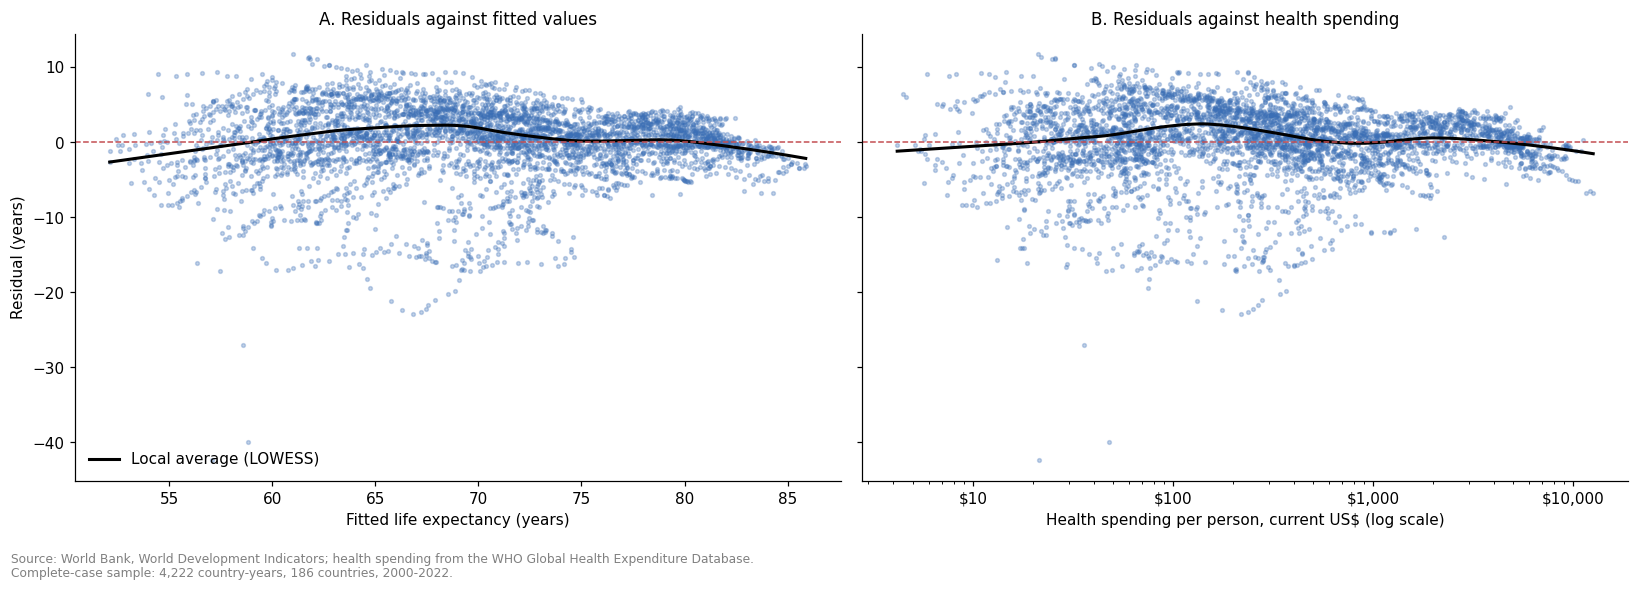

Residual standard deviation (years) by fifth of fitted life expectancy:
Lowest 20%     5.62
20-40%         5.63
40-60%         5.38
60-80%         3.76
Highest 20%    2.28


In [12]:
# Section 4a, Figure 4: residuals against fitted values and against the main predictor (main model (4))
resid, fitted = main_ols.resid, main_ols.fittedvalues
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

axes[0].scatter(fitted, resid, s=6, alpha=0.3, color=BLUE)
trend = lowess(resid, fitted, frac=0.3)
axes[0].plot(trend[:, 0], trend[:, 1], color="black", lw=2, label="Local average (LOWESS)")
axes[0].set(xlabel="Fitted life expectancy (years)", ylabel="Residual (years)", title="A. Residuals against fitted values")

axes[1].scatter(sample["health_exp_pc"], resid, s=6, alpha=0.3, color=BLUE)
trend = lowess(resid, sample["log_health_exp"], frac=0.3)
axes[1].plot(np.exp(trend[:, 0]), trend[:, 1], color="black", lw=2)
axes[1].set_xscale("log")
axes[1].xaxis.set_major_formatter(DOLLARS)
axes[1].set(xlabel="Health spending per person, current US$ (log scale)", title="B. Residuals against health spending")

for ax in axes:
    ax.axhline(0, color="#C44E52", lw=1, ls="--")
axes[0].legend(frameon=False, loc="lower left")
fig.tight_layout()
fig.text(0.01, -0.06, SOURCE_NOTE, fontsize=8, color="gray")
fig.savefig(FIG_DIR / "fig4_residuals.png", dpi=200, bbox_inches="tight")
plt.show()

# A first look at the spread: residual standard deviation in each fifth of the fitted values
fitted_fifth = pd.qcut(fitted, 5, labels=["Lowest 20%", "20-40%", "40-60%", "60-80%", "Highest 20%"])
resid_spread = resid.groupby(fitted_fifth, observed=True).std()
print("Residual standard deviation (years) by fifth of fitted life expectancy:")
print(resid_spread.round(2).to_string())

In [13]:
# Section 4b: constant variance. Breusch-Pagan test, then the main coefficients under three kinds of standard error
bp_lm, bp_p, bp_f, bp_f_p = het_breuschpagan(main_ols.resid, main_ols.model.exog)
print(f"Breusch-Pagan LM statistic = {bp_lm:.1f}, p-value = {bp_p:.2g}  ->  "
      + ("constant variance rejected: use robust standard errors." if bp_p < 0.05
         else "no evidence against constant variance."))

hc3 = smf.ols(FORMULAS[MAIN], data=sample).fit(cov_type="HC3")
se_compare = pd.DataFrame({
    "Coefficient": main.params,
    "SE classical": main_ols.bse,
    "SE robust (HC3)": hc3.bse,
    "SE clustered by country": main.bse,
    "p classical": main_ols.pvalues,
    "p clustered": main.pvalues,
}).loc[["log_health_exp", "log_gdp_pc", "urban_pct"]].rename(index=LABELS)
print("\nTable 5. Main-model coefficients under classical, heteroskedasticity-robust and country-clustered standard errors")
display(se_compare.style.format({c: ("{:.2g}" if c.startswith("p ") else "{:.3f}") for c in se_compare.columns}))

Breusch-Pagan LM statistic = 141.4, p-value = 3.2e-18  ->  constant variance rejected: use robust standard errors.

Table 5. Main-model coefficients under classical, heteroskedasticity-robust and country-clustered standard errors


,Coefficient,SE classical,SE robust (HC3),SE clustered by country,p classical,p clustered
Log health spending per person,1.570,0.111,0.123,0.525,1.7e-44,0.0028
Log GDP per person (PPP),3.963,0.164,0.198,0.835,2.4e-121,2.1e-06
Urban population (%),0.007,0.005,0.006,0.024,0.16,0.78


In [14]:
# Section 4c: variance inflation factors for the three regressors, without and with the year dummies
SLOPES = ["log_health_exp", "log_gdp_pc", "urban_pct"]
X_slopes = sm.add_constant(sample[SLOPES]).to_numpy(dtype=float)
X_main, names_main = main_ols.model.exog, main_ols.model.exog_names
vif_table = pd.DataFrame({
    "VIF, three regressors only": [variance_inflation_factor(X_slopes, i + 1) for i in range(len(SLOPES))],
    "VIF, main model with year effects": [variance_inflation_factor(X_main, names_main.index(v)) for v in SLOPES],
}, index=SLOPES).rename(index=LABELS).round(2)
print("Table 6. Variance inflation factors (above 5 is a warning, above 10 serious)")
display(vif_table)
print("\nCorrelations among the regressors:")
display(sample[SLOPES].corr().rename(index=LABELS, columns=LABELS).round(2))

Table 6. Variance inflation factors (above 5 is a warning, above 10 serious)


,"VIF, three regressors only","VIF, main model with year effects"
Log health spending per person,5.76,6.57
Log GDP per person (PPP),6.26,6.71
Urban population (%),2.30,2.31



Correlations among the regressors:


,Log health spending per person,Log GDP per person (PPP),Urban population (%)
Log health spending per person,1.00,0.91,0.72
Log GDP per person (PPP),0.91,1.00,0.75
Urban population (%),0.72,0.75,1.00


In [15]:
# Section 4d: influential observations. Cook's distance for each country-year, then dropping whole countries
influence = main_ols.get_influence()
infl = sample[["country", "year", "life_exp", "health_exp_pc", "gdp_pc_ppp"]].assign(
    fitted=main_ols.fittedvalues, residual=main_ols.resid,
    leverage=influence.hat_matrix_diag, cooks_d=influence.cooks_distance[0])
cooks_cut = 4 / main_ols.nobs
flagged = infl[infl["cooks_d"] > cooks_cut]
print(f"{len(flagged):,} of {len(infl):,} country-years ({len(flagged) / len(infl):.1%}) have Cook's distance "
      f"above 4/n = {cooks_cut:.5f}.")
print("Countries with the most flagged years:",
      ", ".join(f"{c} ({n})" for c, n in flagged["country"].value_counts().head(8).items()))
print("\nTable 7. The 10 most influential country-years")
display(infl.nlargest(10, "cooks_d").round({"life_exp": 1, "health_exp_pc": 0, "gdp_pc_ppp": 0, "fitted": 1,
                                             "residual": 1, "leverage": 4, "cooks_d": 4}))

# Refit without the flagged country-years
kept = sample.loc[infl["cooks_d"] <= cooks_cut]
no_influential = smf.ols(FORMULAS[MAIN], data=kept).fit(cov_type="cluster",
                                                        cov_kwds={"groups": pd.factorize(kept["iso3"])[0]})

# Drop one country at a time (all of its years), since a country's years move together
X, y = main_ols.model.exog, main_ols.model.endog
j = main_ols.model.exog_names.index("log_health_exp")
iso = sample["iso3"].to_numpy()
leave_one_out = pd.Series({c: np.linalg.lstsq(X[iso != c], y[iso != c], rcond=None)[0][j] for c in np.unique(iso)})
leave_one_out.index = leave_one_out.index.map(sample.drop_duplicates("iso3").set_index("iso3")["country"])

print(f"\nSpending coefficient: full sample {main.params['log_health_exp']:.3f}; without the {len(flagged)} flagged "
      f"country-years {no_influential.params['log_health_exp']:.3f} (clustered SE {no_influential.bse['log_health_exp']:.3f}).")
print(f"Dropping one country at a time, it ranges from {leave_one_out.min():.3f} (without {leave_one_out.idxmin()}) "
      f"to {leave_one_out.max():.3f} (without {leave_one_out.idxmax()}).")

218 of 4,222 country-years (5.2%) have Cook's distance above 4/n = 0.00095.
Countries with the most flagged years: Nigeria (23), Eswatini (22), Naoero (22), Equatorial Guinea (21), Lesotho (19), Namibia (17), Botswana (15), Angola (13)

Table 7. The 10 most influential country-years


,country,year,life_exp,health_exp_pc,gdp_pc_ppp,fitted,residual,leverage,cooks_d
873,Central African Republic,2022,18.8,48.0,1137.0,58.8,-40.0,0.0075,0.0206
860,Central African Republic,2009,14.7,21.0,1403.0,57.1,-42.4,0.0065,0.0201
870,Central African Republic,2019,31.5,36.0,1145.0,58.6,-27.1,0.0072,0.0091
1454,Eswatini,2005,44.0,217.0,7142.0,66.8,-22.9,0.0067,0.0060
1455,Eswatini,2006,44.6,238.0,7585.0,67.2,-22.7,0.0067,0.0059
1456,Eswatini,2007,45.2,252.0,7867.0,67.4,-22.3,0.0066,0.0057
1453,Eswatini,2004,43.9,176.0,6775.0,66.3,-22.4,0.0066,0.0057
1457,Eswatini,2008,45.9,266.0,7926.0,67.5,-21.7,0.0066,0.0053
1458,Eswatini,2009,46.9,280.0,7989.0,67.9,-21.0,0.0066,0.0050
1452,Eswatini,2003,44.6,131.0,6578.0,65.8,-21.1,0.0064,0.0049



Spending coefficient: full sample 1.570; without the 218 flagged country-years 1.741 (clustered SE 0.348).
Dropping one country at a time, it ranges from 1.326 (without Equatorial Guinea) to 1.716 (without Naoero).


**Residuals (Figure 4).** If the model's form is right, the residuals should scatter evenly around zero, with no trend against the fitted values or the main predictor.

- *Shape:* the local average stays close to zero but bends into a mild hump. The model under-predicts life expectancy for countries in the middle of the spending range and over-predicts at both ends. This is the curvature Figure 2 showed: a single slope in log spending is a little too flat at the bottom and too steep at the top. The bend is small next to the spread of the residuals. A quadratic in log spending would be the natural next refinement.
- *Spread:* it isn't even. The residual standard deviation is 5.62 years in the lowest fifth of fitted values, against 2.28 in the highest. The misses are also lopsided. The residuals have a long negative tail (skew −1.49), so the model often predicts far longer lives than people actually have, and rarely the reverse. The largest negative residuals are the Central African Republic's implausible years and Eswatini in 2003–2009, at the height of its HIV epidemic (Table 7).

**Constant variance (Table 5).** The Breusch–Pagan test rejects constant variance decisively (LM = 141.4, p = 3.2 × 10⁻¹⁸), so classical standard errors can't be trusted. Table 5 compares them with heteroskedasticity-robust (HC3) and country-clustered errors:

- *HC3* corrects only for unequal variance. It barely moves the standard error on log spending, from 0.111 to 0.123.
- *Clustering by country* also allows a country's errors to be correlated over time, and they are strongly correlated. The Durbin–Watson statistic is 0.16, far below the 2 that independent errors would give. Clustering raises the standard error to 0.525, 4.7 times the classical one, because a country's 23 years carry much less independent information than 23 different countries would.
- The clustered errors are the ones reported in Table 3. Under them, the spending coefficient is still clearly different from zero (p = 0.0028), and so is income's (p = 2.1 × 10⁻⁶). Urbanization's is not (p = 0.78).

**Multicollinearity (Table 6).** Log spending and log GDP are correlated at 0.91.

- With the year effects included, their VIFs are 6.57 and 6.71 (5.76 and 6.26 without them). That is above the usual warning level of 5, though below the serious level of 10.
- A VIF says how many times larger a coefficient's variance is than it would be if that regressor were uncorrelated with the others. The standard error on spending is therefore about √VIF ≈ 2.6 times what it would otherwise be.
- This doesn't bias the estimates. It means the data can't cleanly separate spending from income, which is part of why the spending interval in Table 4 is so wide.
- Urbanization (VIF 2.31) is not a concern.

**Influential observations (Table 7).** 218 country-years (5.2%) exceed the usual Cook's distance cutoff of 4/n. Most come from three groups of countries whose life expectancy is far below what their spending and income predict:

- southern African countries hit hard by HIV (Eswatini, Lesotho, Namibia, Botswana);
- oil exporters whose income runs well ahead of their health (Nigeria, Equatorial Guinea, Angola);
- Nauru (listed as "Naoero" in the API data).

The three most influential single rows are the Central African Republic's implausible years. Here is how much the spending coefficient moves:

- Dropping all 218 flagged country-years moves it from 1.570 to 1.741 (clustered SE 0.348). The influential points pull it down slightly, not up.
- Because a country's years move together, I also drop one country at a time. The coefficient then ranges from 1.326 (without Equatorial Guinea) to 1.716 (without Nauru). Dropping the Central African Republic leaves it inside that range.
- No single country or group of outliers drives the result. Every version stays positive, between 1.33 and 1.74, against 1.57 in the full sample.

## Section 5: Threats and Conclusion (10 pts)

First the threats: what would have to be true for your main coefficient to be causal, is it, and if not, what your estimate is instead. Then the conclusion: what you found, how confident a reader should be, and what you would do with another month. Half a page. No new results, so there is no code cell here.

**Threats.** For $\hat\beta_1$ to be the causal effect of health spending, spending would have to be as good as randomly assigned across countries with the same income, urbanization and year. It isn't:

1. **Omitted confounders.** Several factors shape both survival and how much a country spends on health, and none is in the model: schooling (especially women's), disease burden (HIV, malaria), conflict and the quality of government. Better-run countries probably spend more *and* live longer for other reasons, which pushes $\hat\beta_1$ up.
2. **Reverse causality.** Longer lives make populations older, and older people need more care, so life expectancy itself raises spending. That also pushes $\hat\beta_1$ up. Epidemics run the other way: they raise spending while life expectancy falls.
3. **Measurement.** Spending converted at market exchange rates understates real spending where prices are low, and that error is systematic, not random noise. In countries without full death registration, life expectancy is itself a model estimate, and the Central African Republic's values look like outright errors (Section 1).
4. **Selection.** The sample drops 15.4% of the panel. Most of the dropped rows are small, rich territories, plus a few crisis states whose missing values are probably extreme (Section 1). The estimate describes countries that report health accounts.

**What the estimate is instead.** $\hat\beta_1$ is a **conditional association**, not a causal effect: the difference in life expectancy between country-years that differ in health spending but share the same income, urbanization and year. It describes the data. It does not predict what happens when a country raises its health budget, and because most of its variation is between countries, it compares countries more than it follows any one country over time.

**Conclusion.**

- *Without controls:* spending and life expectancy are strongly linked. A doubling of spending goes with 2.89 more years.
- *With controls:* holding income constant cuts the spending coefficient by about half (52%, Section 3). Holding income, urbanization and the year constant, a doubling goes with 1.09 more years (95% CI 0.37 to 1.80).
- *Robustness:* the coefficient on log spending stays between 1.33 and 1.74, against 1.57 in the full sample, when influential observations or single countries are dropped (Section 4).

A reader can be confident that, among well-measured countries, this association is real, positive and modest: it survives clustered standard errors and every outlier check. They should be much less confident that it is an effect, since the main threats push it upward.

With another month I would:

1. Add country fixed effects, to ask whether countries that *raise* spending then live longer.
2. Lag spending, because health investment pays off over years.
3. Use the PPP version of health spending (SH.XPD.CHEX.PP.CD) to remove the exchange-rate problem.
4. Add schooling and HIV prevalence as controls.
5. Split spending into government and out-of-pocket shares.

## Appendix

The regression table, the diagnostics output and any extra figures. The appendix does not count toward the 6–8 page limit of the report.

In [16]:
# Appendix A: the main model in full (clustered standard errors). The year dummies appear here, not in Table 3.
print(main.summary())

                            OLS Regression Results                            
Dep. Variable:               life_exp   R-squared:                       0.704
Model:                            OLS   Adj. R-squared:                  0.702
Method:                 Least Squares   F-statistic:                     67.17
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           2.97e-79
Time:                        23:23:24   Log-Likelihood:                -12565.
No. Observations:                4222   AIC:                         2.518e+04
Df Residuals:                    4196   BIC:                         2.535e+04
Df Model:                          25                                         
Covariance Type:              cluster                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          22.8649      5.166     

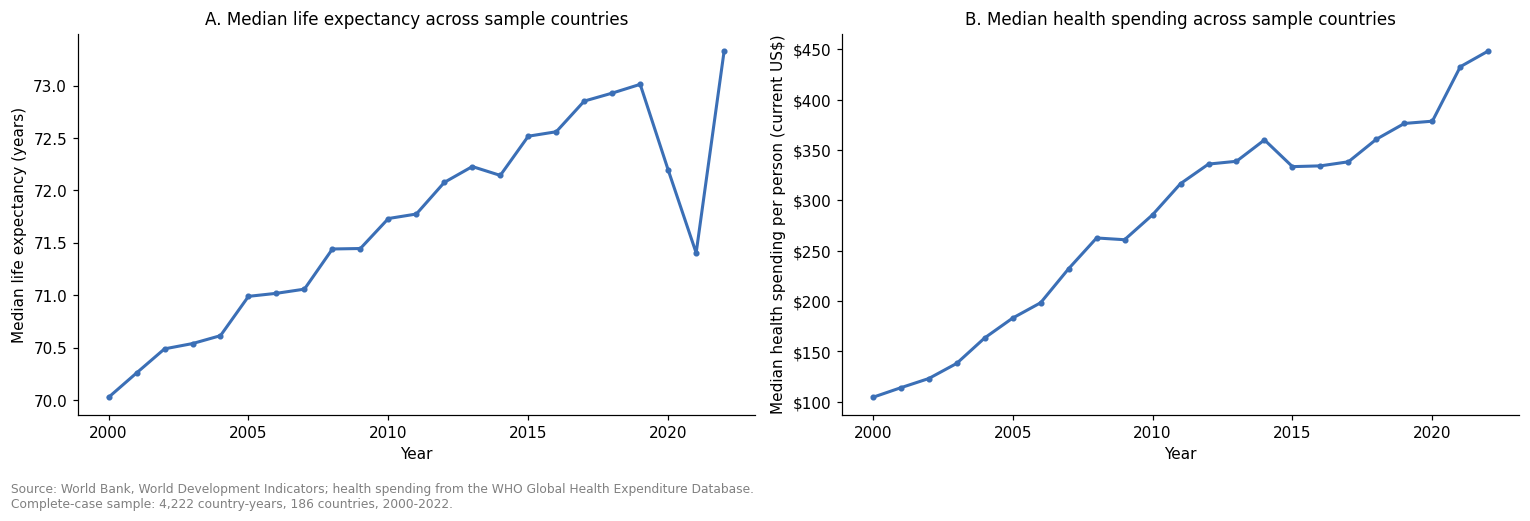

In [17]:
# Appendix B, Figure A1: the common year-to-year movements that the year effects absorb
by_year = sample.groupby("year").agg(life_exp=("life_exp", "median"), health_exp_pc=("health_exp_pc", "median"))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
axes[0].plot(by_year.index, by_year["life_exp"], color=BLUE, lw=2, marker="o", ms=3)
axes[0].set(xlabel="Year", ylabel="Median life expectancy (years)",
            title="A. Median life expectancy across sample countries")
axes[1].plot(by_year.index, by_year["health_exp_pc"], color=BLUE, lw=2, marker="o", ms=3)
axes[1].yaxis.set_major_formatter(DOLLARS)
axes[1].set(xlabel="Year", ylabel="Median health spending per person (current US$)",
            title="B. Median health spending across sample countries")
fig.tight_layout()
fig.text(0.01, -0.06, SOURCE_NOTE, fontsize=8, color="gray")
fig.savefig(FIG_DIR / "figA1_year_trends.png", dpi=200, bbox_inches="tight")
plt.show()

In [18]:
# Appendix C: missing country-years by variable and year, and the economies that never enter the sample
print(f"Missing country-years by variable and year (out of {df['iso3'].nunique()} economies)")
display(is_na.groupby(df["year"]).sum().rename(columns=VARS).T)
never = sorted(set(df["country"]) - set(sample["country"]))
print(f"\n{len(never)} economies never have all four variables in the same year:\n" + ", ".join(never))

Missing country-years by variable and year (out of 217 economies)


year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
Life expectancy at birth (years),0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Health spending per person (current US$),33,33,32,30,30,30,30,30,30,30,...,26,26,26,26,25,24,24,24,25,26
"GDP per person, PPP (constant intl $)",25,25,24,24,24,24,23,22,20,19,...,18,18,18,18,18,18,18,18,18,18
Urban population (% of total),0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



31 economies never have all four variables in the same year:
American Samoa, Aruba, Bermuda, British Virgin Islands, Cayman Islands, Channel Islands, Cuba, Curacao, Eritrea, Faroe Islands, French Polynesia, Gibraltar, Greenland, Guam, Hong Kong SAR, China, Isle of Man, Korea, Dem. People's Rep., Kosovo, Liechtenstein, Macao SAR, China, Monaco, New Caledonia, Northern Mariana Islands, Puerto Rico (US), Sint Maarten (Dutch part), South Sudan, St. Martin (French part), Turks and Caicos Islands, Venezuela, RB, Virgin Islands (U.S.), Yemen, Rep.


## Numbers my report quotes

Every number in your report, each with a name that says where it comes from. A number in the report that this cell does not print is unsupported, and is graded as if it were missing. Keep it the last code cell.

In [19]:
def r(x, d=2):
    """Round a number for the report."""
    return round(float(x), d)


m1 = models["(1)"]
KEPT, DROP = selection.index
VIF_YR, VIF_NO = "VIF, main model with year effects", "VIF, three regressors only"
le, hx, gx, ux = sample["life_exp"], sample["health_exp_pc"], sample["gdp_pc_ppp"], sample["urban_pct"]
lowest, highest = sample.loc[le.idxmin()], sample.loc[le.idxmax()]
lowest5 = sample.nsmallest(5, "life_exp")
b_h = main.params["log_health_exp"]
resid_arr = main_ols.resid.to_numpy()
durbin_watson = np.sum(np.diff(resid_arr) ** 2) / np.sum(resid_arr ** 2)

REPORT_NUMBERS = {
    # Section 1: the panel and what is missing
    "Section 1: economies in the panel": df["iso3"].nunique(),
    "Section 1: country-years in the panel": len(df),
    "Section 1: % of panel missing health spending": r(is_na["health_exp_pc"].mean() * 100, 1),
    "Section 1: % of panel missing PPP GDP per person": r(is_na["gdp_pc_ppp"].mean() * 100, 1),
    "Section 1: % of panel missing life expectancy": r(is_na["life_exp"].mean() * 100, 1),
    "Section 1: % of panel missing urban share": r(is_na["urban_pct"].mean() * 100, 1),
    "Section 1: economies with no health-spending data": int(is_na["health_exp_pc"].groupby(df["iso3"]).all().sum()),
    "Section 1: economies with no PPP GDP data": int(is_na["gdp_pc_ppp"].groupby(df["iso3"]).all().sum()),
    # Section 1: the complete-case sample and who it leaves out
    "Section 1: country-years in the complete-case sample": len(sample),
    "Section 1: countries in the complete-case sample": sample["iso3"].nunique(),
    "Section 1: country-years dropped": len(dropped),
    "Section 1: % of panel dropped": r(len(dropped) / len(df) * 100, 1),
    "Section 1: mean life expectancy, kept rows": selection.loc[KEPT, "Mean"],
    "Section 1: mean life expectancy, dropped rows": selection.loc[DROP, "Mean"],
    "Section 1: 10th percentile life expectancy, kept rows": selection.loc[KEPT, "10th pct"],
    "Section 1: 10th percentile life expectancy, dropped rows": selection.loc[DROP, "10th pct"],
    "Section 1: 90th percentile life expectancy, kept rows": selection.loc[KEPT, "90th pct"],
    "Section 1: 90th percentile life expectancy, dropped rows": selection.loc[DROP, "90th pct"],
    # Section 1: summary statistics (Table 2) and the extremes under it
    "Section 1: life expectancy mean": r(le.mean(), 1),
    "Section 1: life expectancy SD": r(le.std(), 1),
    "Section 1: life expectancy median": r(le.median(), 1),
    "Section 1: life expectancy min": r(le.min(), 1),
    "Section 1: life expectancy max": r(le.max(), 1),
    "Section 1: lowest life expectancy country-year": f"{lowest['country']} {int(lowest['year'])}",
    "Section 1: highest life expectancy country-year": f"{highest['country']} {int(highest['year'])}",
    "Section 1: five lowest life expectancies": "; ".join(f"{row.country} {row.year}: {row.life_exp:.1f}"
                                                          for row in lowest5.itertuples()),
    "Section 1: health spending median, US$": r(hx.median(), 0),
    "Section 1: health spending mean, US$": r(hx.mean(), 0),
    "Section 1: health spending min, US$": r(hx.min(), 1),
    "Section 1: health spending max, US$": r(hx.max(), 0),
    "Section 1: skew of health spending": r(hx.skew()),
    "Section 1: GDP per person median, intl $": r(gx.median(), 0),
    "Section 1: GDP per person mean, intl $": r(gx.mean(), 0),
    "Section 1: skew of GDP per person": r(gx.skew()),
    "Section 1: urban share mean, %": r(ux.mean(), 1),
    "Section 1: urban share SD, %": r(ux.std(), 1),
    "Section 1: urban share min, %": r(ux.min(), 1),
    "Section 1: urban share max, %": r(ux.max(), 1),
    # Section 2
    "Section 2: skew of life expectancy": r(le.skew()),
    "Section 2: skew of log health spending": r(sample["log_health_exp"].skew()),
    "Section 2: skew of log GDP per person": r(sample["log_gdp_pc"].skew()),
    "Section 2: corr(life expectancy, log spending)": r(corr_le_loghealth),
    "Section 2: LOWESS life expectancy at $30, $100, $300, $1,000, $3,000, $10,000":
        ", ".join(f"{v:.1f}" for v in lowess_at),
    "Section 2: LOWESS gain from $30 to $100, years": r(lowess_at[100] - lowess_at[30], 1),
    "Section 2: LOWESS gain from $100 to $1,000, years": r(lowess_at[1000] - lowess_at[100], 1),
    "Section 2: LOWESS gain from $1,000 to $10,000, years": r(lowess_at[10000] - lowess_at[1000], 1),
    "Section 2: LOWESS gain from $3,000 to $10,000, years": r(lowess_at[10000] - lowess_at[3000], 1),
    "Section 2: corr(log spending, log GDP)": r(corr_health_gdp),
    "Section 2: within-quartile years per doubling, smallest": r(min(quartile_slopes.values())),
    "Section 2: within-quartile years per doubling, largest": r(max(quartile_slopes.values())),
    "Section 2: pooled years per doubling, model (1)": r(m1.params["log_health_exp"] * LN2),
    # Section 3: health spending
    "Section 3: spending coefficient, models (1), (2), (3), (4)":
        ", ".join(f"{models[k].params['log_health_exp']:.3f}" for k in FORMULAS),
    "Section 3: clustered SE, log health spending, model (4)": r(main.bse["log_health_exp"], 3),
    "Section 3: clustered p-value, log health spending, model (4)": f"{main.pvalues['log_health_exp']:.2g}",
    "Section 3: years per +10% spending": r(b_h * LN11),
    "Section 3: years per doubling of spending": r(b_h * LN2),
    "Section 3: 95% CI, years per doubling of spending":
        f"{ci.loc['log_health_exp', 0] * LN2:.2f} to {ci.loc['log_health_exp', 1] * LN2:.2f}",
    "Section 3: CI top / CI bottom, doubling of spending": r(ci.loc["log_health_exp", 1] / ci.loc["log_health_exp", 0], 1),
    "Section 3: doubling of spending / SD of life expectancy": r(b_h * LN2 / le.std()),
    "Section 3: % shrink in spending coefficient from adding income": r(shrink * 100, 0),
    # Section 3: income and urbanization
    "Section 3: coefficient on log GDP, model (4)": r(main.params["log_gdp_pc"], 3),
    "Section 3: clustered SE, log GDP, model (4)": r(main.bse["log_gdp_pc"], 3),
    "Section 3: years per doubling of GDP": r(main.params["log_gdp_pc"] * LN2),
    "Section 3: 95% CI, years per doubling of GDP":
        f"{ci.loc['log_gdp_pc', 0] * LN2:.2f} to {ci.loc['log_gdp_pc', 1] * LN2:.2f}",
    "Section 3: GDP doubling / spending doubling": r(main.params["log_gdp_pc"] / b_h, 1),
    "Section 3: urban coefficient, models (2) and (4)": f"{models['(2)'].params['urban_pct']:.3f}, {main.params['urban_pct']:.3f}",
    "Section 3: clustered SE, urban %, model (4)": r(main.bse["urban_pct"], 3),
    "Section 3: years per +10 points urban": r(main.params["urban_pct"] * 10),
    "Section 3: 95% CI, years per +10 points urban":
        f"{ci.loc['urban_pct', 0] * 10:.2f} to {ci.loc['urban_pct', 1] * 10:.2f}",
    "Section 3: R-squared, models (1), (2), (3), (4)": ", ".join(f"{models[k].rsquared:.3f}" for k in FORMULAS),
    # Section 4: residuals
    "Section 4: residual SD, lowest fifth of fitted values": r(resid_spread.iloc[0]),
    "Section 4: residual SD, highest fifth of fitted values": r(resid_spread.iloc[-1]),
    "Section 4: skew of residuals": r(main_ols.resid.skew()),
    "Section 4: Durbin-Watson statistic": r(durbin_watson),
    # Section 4: constant variance
    "Section 4: Breusch-Pagan LM statistic": r(bp_lm, 1),
    "Section 4: Breusch-Pagan p-value": f"{bp_p:.2g}",
    "Section 4: SE on log spending, classical / HC3 / clustered":
        f"{main_ols.bse['log_health_exp']:.3f} / {hc3.bse['log_health_exp']:.3f} / {main.bse['log_health_exp']:.3f}",
    "Section 4: clustered / classical SE, log spending": r(main.bse["log_health_exp"] / main_ols.bse["log_health_exp"], 1),
    "Section 4: clustered p-values, log spending / log GDP / urban %": " / ".join(f"{main.pvalues[v]:.2g}" for v in SLOPES),
    # Section 4: multicollinearity
    "Section 4: VIF with year effects, log spending / log GDP / urban %":
        " / ".join(f"{vif_table.loc[LABELS[v], VIF_YR]:.2f}" for v in SLOPES),
    "Section 4: VIF without year effects, log spending / log GDP / urban %":
        " / ".join(f"{vif_table.loc[LABELS[v], VIF_NO]:.2f}" for v in SLOPES),
    "Section 4: sqrt(VIF), log spending": r(np.sqrt(vif_table.loc[LABELS["log_health_exp"], VIF_YR]), 1),
    # Section 4: influence
    "Section 4: country-years above Cook's 4/n": len(flagged),
    "Section 4: % of sample above Cook's 4/n": r(len(flagged) / len(infl) * 100, 1),
    "Section 4: countries with the most flagged years":
        ", ".join(f"{c} ({n})" for c, n in flagged["country"].value_counts().head(8).items()),
    "Section 4: 10 most influential country-years":
        "; ".join(f"{row.country} {row.year}" for row in infl.nlargest(10, "cooks_d").itertuples()),
    "Section 4: spending coefficient without flagged rows (clustered SE)":
        f"{no_influential.params['log_health_exp']:.3f} ({no_influential.bse['log_health_exp']:.3f})",
    "Section 4: leave-one-country-out range of the spending coefficient":
        f"{leave_one_out.min():.3f} (without {leave_one_out.idxmin()}) to {leave_one_out.max():.3f} (without {leave_one_out.idxmax()})",
    "Section 4: spending coefficient without the Central African Republic": r(leave_one_out["Central African Republic"], 3),
}

for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")

Section 1: economies in the panel: 217
Section 1: country-years in the panel: 4991
Section 1: % of panel missing health spending: 12.9
Section 1: % of panel missing PPP GDP per person: 9.4
Section 1: % of panel missing life expectancy: 0.0
Section 1: % of panel missing urban share: 0.0
Section 1: economies with no health-spending data: 24
Section 1: economies with no PPP GDP data: 18
Section 1: country-years in the complete-case sample: 4222
Section 1: countries in the complete-case sample: 186
Section 1: country-years dropped: 769
Section 1: % of panel dropped: 15.4
Section 1: mean life expectancy, kept rows: 70.1
Section 1: mean life expectancy, dropped rows: 74.6
Section 1: 10th percentile life expectancy, kept rows: 57.8
Section 1: 10th percentile life expectancy, dropped rows: 63.1
Section 1: 90th percentile life expectancy, kept rows: 80.9
Section 1: 90th percentile life expectancy, dropped rows: 82.4
Section 1: life expectancy mean: 70.1
Section 1: life expectancy SD: 8.7
Sectio

## Checkpoints

In Colab, *File › Save a copy in GitHub* makes a commit each time you use it. Save at each checkpoint so the commit history shows it.

- [ ] **Mon 26 Oct:** your question and data source, posted in the Midterm checkpoint 1 discussion.
- [ ] **Mon 2 Nov:** your data loaded and your summary table, committed to your repository.
- [ ] **Fri 6 Nov:** a draft of your model, committed.
- [ ] **Mon 9 Nov, 11:59pm:** the project is due.

## Before you submit

- [ ] A Colab notebook with all your analysis, cleanly organised.
- [ ] A written report, 6 to 8 pages of text, uploaded as a PDF.
- [ ] A GitHub repository containing both, with a `README.md` you wrote yourself.
- [ ] **Question and data provenance (20):** A defensible measurable question; data described as a measurement product; missingness mechanism identified and defended; interpretable summary table
- [ ] **Descriptive evidence (20):** Two or more figures each making a stated point; captions state findings not variables; Chapter 3 standards met
- [ ] **Model and interpretation (25):** Properly formatted regression table; two coefficients interpreted in full including units and magnitude; every control justified by role
- [ ] **Diagnostics (20):** Residuals, heteroskedasticity, VIF and influence all run and interpreted; robust errors used where warranted
- [ ] **Threats and conclusion (10):** The causal claim assessed in plain terms; the estimand correctly labelled if not causal; conclusion adds no new results
- [ ] **Repository, checkpoints and reproducibility (5):** Public GitHub repo containing the notebook and the report; the two committed checkpoints visible in the commit history; data included or its download documented; a self-written README giving the question, the source, how to run it and the headline finding
- [ ] The Colab notebook is shared with *Anyone with the link*, and the link is in the Canvas submission box.
- [ ] Every number in the report is printed by the *Numbers my report quotes* cell.
- [ ] *File › Save a copy in GitHub*, path `Midterm Project/Econ_3916_Midterm.ipynb`.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.